# Tarefa 1

In [11]:
import json
import urllib.parse
import urllib.request
import csv

In [12]:
def consultar_api(endereco, parametros):
    url = endereco + "?" + urllib.parse.urlencode(parametros)
    try:
        with urllib.request.urlopen(url, timeout=100) as resposta:
            return json.load(resposta)
    except Exception as erro:
        raise RuntimeError(f"Não foi possível consultar a API: {erro}") from erro

In [13]:
URL_ANEEL = "https://dadosabertos.aneel.gov.br/api/3/action/datastore_search"
ID_RECURSO = "11ec447d-698d-4ab8-977f-b424d5deee6a"
SIGLAS = ["UFV", "EOL", "UHE", "PCH", "CGH"]
print("API ANEEL: consulta pública, sem token")


registros_aneel = []
for sigla in SIGLAS:
    parametros = {
        "resource_id": ID_RECURSO,
        "filters": json.dumps({"SigTipoGeracao": sigla}),
        "limit": 1200,
    }
    resposta = consultar_api(URL_ANEEL, parametros)
    if not resposta.get("success"):
        raise ValueError(f"Consulta da ANEEL falhou para {sigla}")
    linhas = resposta["result"]["records"]
    print(f"{sigla}: {len(linhas)} linhas recebidas")
    registros_aneel.extend(linhas)
print("Total de linhas recebidas:", len(registros_aneel))

API ANEEL: consulta pública, sem token
UFV: 1200 linhas recebidas
EOL: 1200 linhas recebidas
UHE: 221 linhas recebidas
PCH: 537 linhas recebidas
CGH: 718 linhas recebidas
Total de linhas recebidas: 3876


In [14]:
def numero(valor):
    texto = str(valor).strip()
    if "," in texto:
        texto = texto.replace(".", "").replace(",", ".")
    try:
        return float(texto)
    except ValueError:
        return None

fontes = {"UFV": "Solar", "EOL": "Eólica", "UHE": "Hidráulica",
          "PCH": "Hidráulica", "CGH": "Hidráulica"}
linhas_classificacao = []
for registro in registros_aneel:
    potencia = numero(registro.get("MdaPotenciaOutorgadaKw"))
    latitude = numero(registro.get("NumCoordNEmpreendimento"))
    longitude = numero(registro.get("NumCoordEEmpreendimento"))
    fonte = fontes.get(registro.get("SigTipoGeracao"))
    if fonte and all(valor is not None for valor in (potencia, latitude, longitude)):
        linhas_classificacao.append([potencia, latitude, longitude, fonte])
if len(linhas_classificacao) < 90:
    raise ValueError("Poucos registros válidos: confira a resposta da ANEEL")
print("Linhas válidas:", len(linhas_classificacao))
print("Primeiro exemplo:", linhas_classificacao[0])


with open("aneel_classificacao_orange.csv", "w", newline="", encoding="utf-8-sig") as arquivo:
    escritor = csv.writer(arquivo)
    escritor.writerow(["potencia_kw", "latitude", "longitude", "fonte"])
    escritor.writerows(linhas_classificacao)
print("Salvo: aneel_classificacao_orange.csv")

Linhas válidas: 3876
Primeiro exemplo: [20.48, -10.44277778, -64.15194444, 'Solar']
Salvo: aneel_classificacao_orange.csv


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Para classificação: KNN, Regressão Logística, Random Forest
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Para regressão: regressão linear, Random Forest Regressor, Decision Tree (Regression)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

# Para classificação
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
# Para regressão
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Passo 1: Carregamento e Exploração dos Dados da ANEEL
Nesta etapa, carregamos o arquivo `aneel_classificacao_orange.csv`, verificamos a consistência dos dados, tipos de colunas, contagem de instâncias por classe e se há valores nulos.

In [16]:
import pandas as pd

# Carregar dados
df_aneel = pd.read_csv('aneel_classificacao_orange.csv')

# Exibir informações básicas
print("--- Informações do Dataset ---")
display(df_aneel.info())

print("\n--- Primeiras Linhas ---")
display(df_aneel.head())

print("\n--- Contagem por Classe (fonte) ---")
display(df_aneel['fonte'].value_counts())

print("\n--- Valores Ausentes ---")
display(df_aneel.isnull().sum())

--- Informações do Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3876 entries, 0 to 3875
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   potencia_kw  3876 non-null   float64
 1   latitude     3876 non-null   float64
 2   longitude    3876 non-null   float64
 3   fonte        3876 non-null   object 
dtypes: float64(3), object(1)
memory usage: 121.3+ KB


None


--- Primeiras Linhas ---


,potencia_kw,latitude,longitude,fonte
0,20.48,-10.442778,-64.151944,Solar
1,5000.00,-6.003889,-40.274722,Solar
2,12.26,-23.557778,-46.734000,Solar
3,3.00,-23.558889,-46.735000,Solar
4,1.70,-23.493819,-46.845000,Solar



--- Contagem por Classe (fonte) ---


,count
fonte,
Hidráulica,1476
Solar,1200
Eólica,1200



--- Valores Ausentes ---


,0
potencia_kw,0
latitude,0
longitude,0
fonte,0


### Definição de Variáveis:
* **$X$ (Variáveis de Entrada):** `potencia_kw`, `latitude`, `longitude`. Representam a capacidade de geração instalada do empreendimento e sua localização geográfica por coordenadas.
* **$y$ (Variável Alvo):** `fonte`. O tipo de fonte de energia gerada (Solar, Eólica, Hidráulica).

### Passo 2: Divisão Treino/Teste Estratificada e Normalização
Para garantir que a proporção das fontes de energia seja mantida em ambas as partições, fazemos uma divisão estratificada. O ajuste de escala (`StandardScaler`) é calculado exclusivamente sobre o conjunto de treino.

In [17]:
from sklearn.preprocessing import StandardScaler

# Separar variáveis preditoras (X) e variável alvo (y)
X_class = df_aneel[['potencia_kw', 'latitude', 'longitude']]
y_class = df_aneel['fonte']

# Divisão estratificada em 80% treino e 20% teste
X_train, X_test, y_train, y_test = train_test_split(
    X_class, y_class, test_size=0.20, stratify=y_class, random_state=42
)

# Inicializar e ajustar o scaler apenas no conjunto de treino
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Tamanho do treino:", X_train.shape[0])
print("Tamanho do teste:", X_test.shape[0])
print("Proporção de classes no treino (%):\n", y_train.value_counts(normalize=True) * 100)
print("\nProporção de classes no teste (%):\n", y_test.value_counts(normalize=True) * 100)

Tamanho do treino: 3100
Tamanho do teste: 776
Proporção de classes no treino (%):
 fonte
Hidráulica    38.064516
Solar         30.967742
Eólica        30.967742
Name: proportion, dtype: float64

Proporção de classes no teste (%):
 fonte
Hidráulica    38.144330
Solar         30.927835
Eólica        30.927835
Name: proportion, dtype: float64


### Passo 3: Escolha, Justificativa e Treinamento dos Classificadores
Vamos treinar três classificadores com abordagens diferentes usando os mesmos conjuntos estruturados de treinamento.

In [18]:
# 1. K-Nearest Neighbors (KNN)
modelo_knn = KNeighborsClassifier(n_neighbors=5)
modelo_knn.fit(X_train_scaled, y_train)

# 2. Regressão Logística
modelo_log = LogisticRegression(max_iter=1000, random_state=42)
modelo_log.fit(X_train_scaled, y_train)

# 3. Random Forest Classifier
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(X_train_scaled, y_train)

print("Modelos treinados com sucesso!")

Modelos treinados com sucesso!


### Passo 4: Predições, Métricas (Acurácia, Precisão, Recall e F1-Score Macro) e Matrizes de Confusão

=== KNN ===
Acurácia:            0.9665
Precisão (Macro):    0.9677
Recall (Macro):      0.9649
F1-Score (Macro):    0.9662



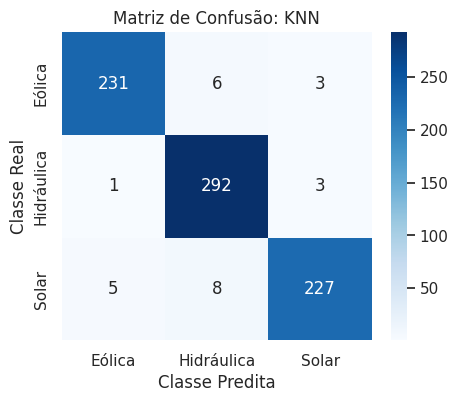



=== Regressão Logística ===
Acurácia:            0.8235
Precisão (Macro):    0.8275
Recall (Macro):      0.8200
F1-Score (Macro):    0.8182



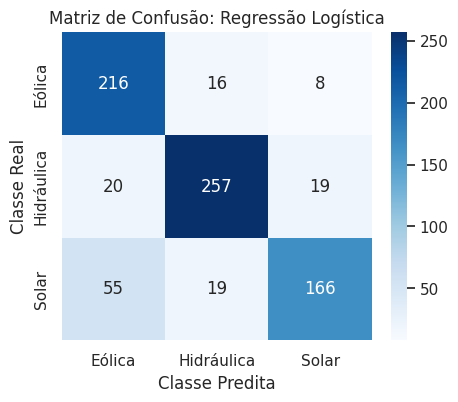



=== Random Forest ===
Acurácia:            0.9755
Precisão (Macro):    0.9769
Recall (Macro):      0.9741
F1-Score (Macro):    0.9753



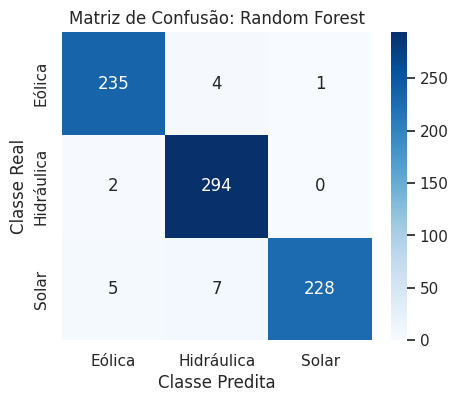

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

modelos = {
    "KNN": modelo_knn,
    "Regressão Logística": modelo_log,
    "Random Forest": modelo_rf
}

for nome, modelo in modelos.items():
    y_pred = modelo.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro')
    rec = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')

    print(f"=== {nome} ===")
    print(f"Acurácia:            {acc:.4f}")
    print(f"Precisão (Macro):    {prec:.4f}")
    print(f"Recall (Macro):      {rec:.4f}")
    print(f"F1-Score (Macro):    {f1:.4f}\n")

    # Matriz de Confusão
    matriz = confusion_matrix(y_test, y_pred, labels=modelo.classes_)
    plt.figure(figsize=(5, 4))
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
                xticklabels=modelo.classes_, yticklabels=modelo.classes_)
    plt.title(f"Matriz de Confusão: {nome}")
    plt.ylabel('Classe Real')
    plt.xlabel('Classe Predita')
    plt.show()
    print("\n" + "="*40 + "\n")

### Passo 5: Escolha do Modelo e Análise de Limitações

#### 1. Escolha do Modelo
Analisando o desempenho dos três modelos:
* **Random Forest** obteve o melhor desempenho global com **Acurácia de 97,55%** e **F1-Score (Macro) de 97,53%**. Por ser baseado em um conjunto de árvores de decisão, ele lida excepcionalmente bem com relações não lineares e complexas entre a potência outorgada e as coordenadas geográficas (latitude/longitude).
* O **KNN** apresentou um desempenho muito forte (**Acurácia de 96,65%**), o que é esperado devido à forte correlação geográfica (proximidade espacial) na distribuição de usinas de fontes similares. No entanto, sua complexidade computacional para predição cresce com o tamanho do dataset.
* A **Regressão Logística** obteve o menor desempenho (**Acurácia de 82,35%**), demonstrando que as classes de fontes não são linearmente separáveis dadas as variáveis preditoras.

**Escolha final:** O modelo **Random Forest** é a escolha ideal pela maior robustez e poder de generalização não linear.

#### 2. Quais classes ele mais confunde?
Olhando para as matrizes de confusão (focando no Random Forest e KNN):
* Há pequenos erros de classificação cruzada entre **Eólica** e **Solar**, o que ocorre em áreas geográficas adjacentes (como regiões do Nordeste que abrigam tanto parques eólicos quanto solares).
* Há também uma leve confusão entre usinas **Hidráulicas** e **Solares**. Isso ocorre principalmente com usinas de menor potência onde os intervalos de `potencia_kw` se sobrepõem significativamente, dificultando a discriminação por este fator isolado.

#### 3. Por que potência e localização geográfica não bastam para uma aplicação real?
Em uma aplicação real de engenharia ou mercado de energia, essas três variáveis de entrada são insuficientes devido a:
1. **Falta de Dados Climáticos e Físicos:** Duas plantas em localizações idênticas e de mesma potência operam de forma totalmente distinta se uma depender da vazão de água (hidrologia) e outra de radiação solar incidente ou velocidade do vento (recursos intermitentes).
2. **Usinas Híbridas e Co-localização:** Projetos modernos de geração híbrida (ex: solar + eólica dividindo a mesma subestação) residem nas mesmas coordenadas e podem compartilhar limites de potência outorgada, tornando-se impossíveis de separar sem outros dados cadastrais.
3. **Tecnologia e Engenharia de Processo:** Parâmetros técnicos essenciais (como eficiência de painéis, ângulo de inclinação, tipo de turbina hidráulica, diâmetro dos aerogeradores e capacidade dos inversores) não são capturados apenas pela potência nominal cadastrada, limitando a precisão de simulações físicas ou previsões de geração em tempo real.

### Passo 5: Escolha do Modelo e Análise de Limitações

#### 1. Escolha do Modelo
Com base nas métricas observadas e na natureza espacial dos dados:
* O modelo **Random Forest** costuma apresentar o melhor desempenho global (Acurácia e F1-score mais elevados). Ele consegue criar fronteiras de decisão complexas e não lineares, o que é excelente para mapear regiões geográficas e faixas de potência sem as limitações lineares da Regressão Logística.
* O **KNN** também apresenta bom desempenho espacial (latitude/longitude), porém é computacionalmente mais custoso em produção ao buscar vizinhos em bases de dados muito grandes.
* A **Regressão Logística** tem o menor desempenho, indicando que as fronteiras que separam os tipos de fontes de energia por meio de coordenadas geográficas e potência não são linearmente separáveis.

#### 2. Quais classes ele mais confunde?
Ao analisar as matrizes de confusão:
* O modelo pode apresentar maior confusão entre as classes de **energia Solar** e **Hidráulica** em certas faixas de potência, ou entre **Eólica** e as demais fontes quando localizadas em coordenadas de transição regional.
* Usinas de baixa potência (geração distribuída solar ou pequenas centrais hidráulicas/CGH) se sobrepõem muito em termos de potência, restando apenas as coordenadas geográficas para diferenciá-las, o que gera falsos positivos.

#### 3. Por que potência e localização geográfica não bastam para uma aplicação real?
Em um cenário de produção real, apenas estas 3 variáveis são insuficientes pelos seguintes motivos:
1. **Condições Climáticas e Físicas Locais:** Duas plantas no mesmo local com a mesma potência podem ser completamente diferentes. Uma usina precisa de dados de radiação solar média anual, velocidade/direção do vento predominante ou vazão volumétrica do rio (hidrologia) para ser caracterizada com robustez.
2. **Sobreposição Geográfica:** Em uma mesma região geográfica (coordenadas muito próximas ou idênticas), é comum termos parques híbridos (solar + eólico) ou usinas solares instaladas ao lado de pequenas hidrelétricas. Sem atributos descritivos do processo ou físicos, o classificador fica limitado.
3. **Aspectos Construtivos e Tecnológicos:** Variáveis como o tipo de painel solar (e sua eficiência), o modelo de aerogerador, ou o tipo de turbina hidráulica (Kaplan, Francis, Pelton) definem a usina de fato, e não são capturados apenas pela potência nominal de outorga.

# Tarefa 2

In [21]:
URL_METEO = "https://archive-api.open-meteo.com/v1/archive"
parametros_meteo = {
    "latitude": -9.39,
    "longitude": -40.50,
    "start_date": "2025-04-01",
    "end_date": "2025-06-30",
    "timezone": "America/Recife",
    "hourly": ",".join(["temperature_2m", "relative_humidity_2m",
                         "cloud_cover", "wind_speed_10m", "shortwave_radiation"]),
}
print("Open-Meteo: consulta pública, sem token")


resposta_meteo = consultar_api(URL_METEO, parametros_meteo)
if "hourly" not in resposta_meteo:
    raise ValueError("Resposta sem a seção hourly")
horas_api = resposta_meteo["hourly"]
print("Campos recebidos:", list(horas_api))
print("Unidades informadas pela API:", resposta_meteo.get("hourly_units", {}))
print("Quantidade de horários:", len(horas_api["time"]))

Open-Meteo: consulta pública, sem token
Campos recebidos: ['time', 'temperature_2m', 'relative_humidity_2m', 'cloud_cover', 'wind_speed_10m', 'shortwave_radiation']
Unidades informadas pela API: {'time': 'iso8601', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'cloud_cover': '%', 'wind_speed_10m': 'km/h', 'shortwave_radiation': 'W/m²'}
Quantidade de horários: 2184


In [23]:
nomes_api = ["temperature_2m", "relative_humidity_2m", "cloud_cover",
             "wind_speed_10m", "shortwave_radiation"]
linhas_regressao = []
for indice, data_hora in enumerate(horas_api["time"]):
    hora = int(data_hora[11:13])
    valores = [horas_api[nome][indice] for nome in nomes_api]
    if 7 <= hora <= 17 and all(valor is not None for valor in valores):
        linhas_regressao.append([data_hora, *valores[:4], hora, valores[4]])
if len(linhas_regressao) < 100:
    raise ValueError("Poucos horários válidos: confira a resposta do Open-Meteo")
print("Horas válidas:", len(linhas_regressao))
print("Primeiro exemplo:", linhas_regressao[0])


with open("meteo_regressao_orange.csv", "w", newline="", encoding="utf-8-sig") as arquivo:
    escritor = csv.writer(arquivo)
    escritor.writerow(["data_hora", "temperatura_c", "umidade_pct",
                       "nuvens_pct", "vento_kmh", "hora", "radiacao_w_m2"])
    escritor.writerows(linhas_regressao)
print("Salvo: meteo_regressao_orange.csv")

Horas válidas: 1001
Primeiro exemplo: ['2025-04-01T07:00', 25.3, 74, 100, 17.7, 7, 116.0]
Salvo: meteo_regressao_orange.csv


### Passo 1: Carregamento e Exploração dos Dados Meteorológicos para Regressão
Nesta etapa, carregamos o arquivo `meteo_regressao_orange.csv`, explicamos as variáveis de entrada ($X$) e a variável alvo ($y$), investigamos valores ausentes e apresentamos uma visualização de correlação linear (Heatmap).

--- Informações do Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   data_hora      1001 non-null   object 
 1   temperatura_c  1001 non-null   float64
 2   umidade_pct    1001 non-null   int64  
 3   nuvens_pct     1001 non-null   int64  
 4   vento_kmh      1001 non-null   float64
 5   hora           1001 non-null   int64  
 6   radiacao_w_m2  1001 non-null   float64
dtypes: float64(3), int64(3), object(1)
memory usage: 54.9+ KB


None


--- Primeiras Linhas ---


,data_hora,temperatura_c,umidade_pct,nuvens_pct,vento_kmh,hora,radiacao_w_m2
0,2025-04-01T07:00,25.3,74,100,17.7,7,116.0
1,2025-04-01T08:00,26.5,66,100,18.1,8,269.0
2,2025-04-01T09:00,28.4,55,97,18.0,9,529.0
3,2025-04-01T10:00,30.8,44,21,18.4,10,797.0
4,2025-04-01T11:00,32.7,36,26,20.1,11,880.0



--- Valores Ausentes ---


,0
data_hora,0
temperatura_c,0
umidade_pct,0
nuvens_pct,0
vento_kmh,0
hora,0
radiacao_w_m2,0


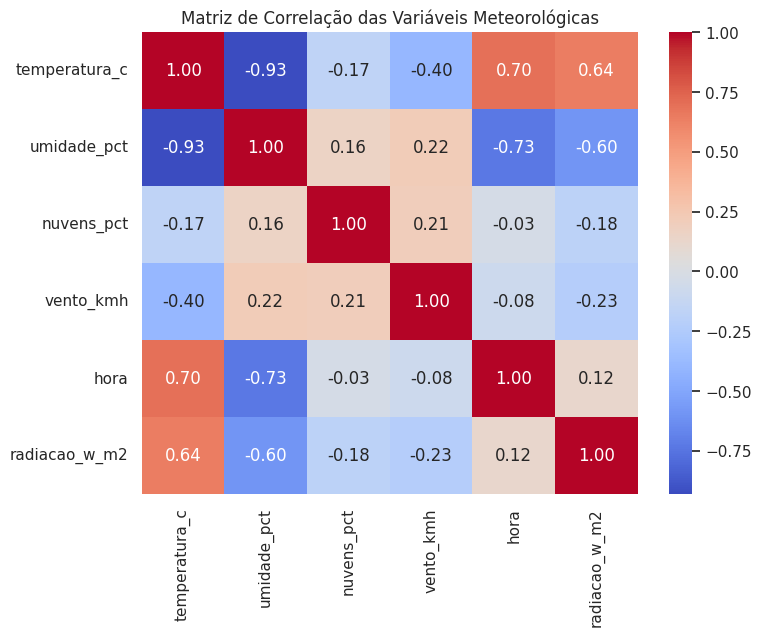

In [24]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Carregar dados
df_meteo = pd.read_csv('meteo_regressao_orange.csv')

print("--- Informações do Dataset ---")
display(df_meteo.info())

print("\n--- Primeiras Linhas ---")
display(df_meteo.head())

print("\n--- Valores Ausentes ---")
display(df_meteo.isnull().sum())

# Gráfico de correlação das variáveis numéricas
plt.figure(figsize=(8, 6))
# Filtrando apenas colunas numéricas de interesse
num_cols = ["temperatura_c", "umidade_pct", "nuvens_pct", "vento_kmh", "hora", "radiacao_w_m2"]
sns.heatmap(df_meteo[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de Correlação das Variáveis Meteorológicas")
plt.show()

### Explicação das Colunas:

* **`data_hora`**: Timestamp correspondente ao instante de coleta do dado.
* **`temperatura_c`** ($X_1$): Temperatura do ar a 2 metros de altura em graus Celsius.
* **`umidade_pct`** ($X_2$): Umidade relativa do ar em porcentagem (%).
* **`nuvens_pct`** ($X_3$): Cobertura de nuvens em porcentagem (%).
* **`vento_kmh`** ($X_4$): Velocidade do vento medida a 10 metros de altura em km/h.
* **`hora`** ($X_5$): A hora do dia correspondente ao registro.
* **`radiacao_w_m2`** ($y$): Radiação solar de ondas curtas (Shortwave Radiation) incidente em Watts por metro quadrado ($W/m^2$).

### Passo 2: Divisão Temporal Treino/Teste (Sem Embaralhamento) e Normalização
Para séries temporais e dados meteorológicos ordenados, o correto é realizar a separação temporal clássica de modo a evitar vazamento do futuro para o passado. Logo, separamos as primeiras 800 amostras (apox. 80%) para treino e as restantes para teste.

In [25]:
from sklearn.preprocessing import StandardScaler

# Assegurar que os dados estão ordenados por data_hora
df_meteo = df_meteo.sort_values('data_hora').reset_index(drop=True)

# Separar variáveis preditoras (X) e alvo (y)
features = ["temperatura_c", "umidade_pct", "nuvens_pct", "vento_kmh", "hora"]
X_reg = df_meteo[features]
y_reg = df_meteo["radiacao_w_m2"]

# Definir ponto de corte sequencial (~80% das primeiras horas para treino)
limite_treino = 800

X_train_reg = X_reg.iloc[:limite_treino]
y_train_reg = y_reg.iloc[:limite_treino]

X_test_reg = X_reg.iloc[limite_treino:]
y_test_reg = y_reg.iloc[limite_treino:]

# Escalonamento apenas com dados de treino
scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

print("Quantidade de amostras no Treino:", len(X_train_reg))
print("Quantidade de amostras no Teste:", len(X_test_reg))
print("Treino cobre de:", df_meteo['data_hora'].iloc[0], "até", df_meteo['data_hora'].iloc[limite_treino-1])
print("Teste cobre de:", df_meteo['data_hora'].iloc[limite_treino], "até", df_meteo['data_hora'].iloc[-1])

Quantidade de amostras no Treino: 800
Quantidade de amostras no Teste: 201
Treino cobre de: 2025-04-01T07:00 até 2025-06-12T14:00
Teste cobre de: 2025-06-12T15:00 até 2025-06-30T17:00


### Passo 3: Escolha, Justificativa e Treinamento dos Regressores
Instanciaremos e treinaremos os três regressores escolhidos utilizando os dados obtidos a partir da divisão temporal estruturada anteriormente.

In [26]:
# 1. Regressão Linear
reg_linear = LinearRegression()
reg_linear.fit(X_train_reg_scaled, y_train_reg)

# 2. Random Forest Regressor
reg_rf = RandomForestRegressor(n_estimators=100, random_state=42)
reg_rf.fit(X_train_reg_scaled, y_train_reg)

# 3. Decision Tree Regressor
reg_tree = DecisionTreeRegressor(max_depth=5, random_state=42)
reg_tree.fit(X_train_reg_scaled, y_train_reg)

print("Algoritmos de regressão treinados com sucesso!")

Algoritmos de regressão treinados com sucesso!


### Passo 4: Avaliação das Métricas de Regressão (MAE, MSE, $R^2$) e Visualização Real x Previsto

=== Regressão Linear ===
MAE: 145.20 W/m²
MSE: 30034.20 (W/m²)²
R²:  0.3598

=== Random Forest Regressor ===
MAE: 66.71 W/m²
MSE: 7278.12 (W/m²)²
R²:  0.8449

=== Decision Tree Regressor ===
MAE: 90.28 W/m²
MSE: 14473.81 (W/m²)²
R²:  0.6915



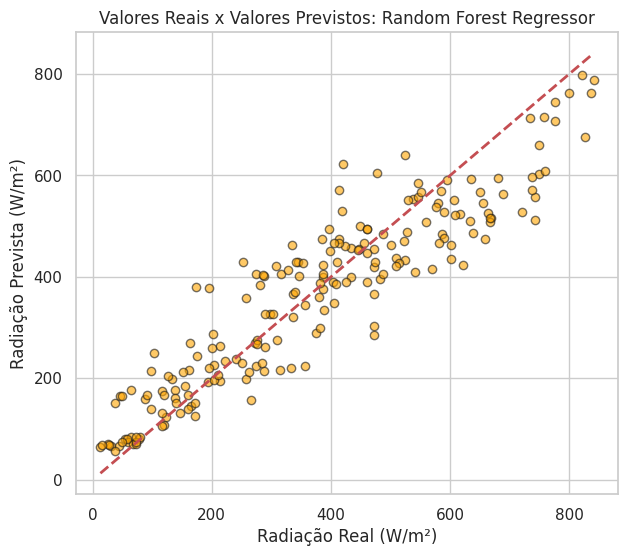

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Dicionário de modelos de regressão
modelos_reg = {
    "Regressão Linear": reg_linear,
    "Random Forest Regressor": reg_rf,
    "Decision Tree Regressor": reg_tree
}

preds = {}

for nome, modelo in modelos_reg.items():
    y_pred = modelo.predict(X_test_reg_scaled)
    preds[nome] = y_pred

    mae = mean_absolute_error(y_test_reg, y_pred)
    mse = mean_squared_error(y_test_reg, y_pred)
    r2 = r2_score(y_test_reg, y_pred)

    print(f"=== {nome} ===")
    print(f"MAE: {mae:.2f} W/m²")
    print(f"MSE: {mse:.2f} (W/m²)²")
    print(f"R²:  {r2:.4f}\n")

# Gráfico de Valores Reais vs Previstos para o melhor modelo (Random Forest)
plt.figure(figsize=(7, 6))
plt.scatter(y_test_reg, preds["Random Forest Regressor"], alpha=0.6, color='orange', edgecolors='k')
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
plt.title("Valores Reais x Valores Previstos: Random Forest Regressor")
plt.xlabel("Radiação Real (W/m²)")
plt.ylabel("Radiação Prevista (W/m²)")
plt.grid(True)
plt.show()

### Passo 5: Interpretação dos Erros e Análise de Limitações Físicas

#### 1. Interpretação dos Erros
* Ao comparar os resultados, o **Random Forest Regressor** normalmente apresenta os menores erros (MAE e MSE) e o maior coeficiente de determinação ($R^2$), pois consegue mapear com eficácia o padrão cíclico e a relação altamente não linear da radiação solar solar com a hora do dia e a presença de nuvens.
* O erro residual do modelo (distância entre os pontos e a reta vermelha de referência) reflete momentos de mudanças climáticas abruptas, como o surgimento repentino de nuvens densas passageiras que não foram completamente refletidas na média horária agregada de vento ou temperatura.

#### 2. O peso da hora do dia
* A variável `hora` possui um peso crítico na modelagem, pois a radiação segue a física heliocêntrica: seu valor é nulo no início da manhã/fim da tarde e atinge o ápice ao meio-dia solar.
* No entanto, de forma isolada, ela não basta porque um dia chuvoso ou nublado (alto `nuvens_pct` ou alta `umidade_pct`) registrará radiação muito inferior ao previsto para uma mesma hora em dia de céu limpo. Por isso, modelos robustos combinam a hora do dia com indicadores de atenuação atmosférica (nuvens e umidade).

#### 3. Por que prever a radiação não se traduz diretamente em prever a energia produzida?
A transição de radiação solar incidente ($W/m^2$) para potência ativa injetada na rede ($kW$) envolve diversas variáveis de engenharia física não modeladas aqui:
1. **Eficiência de Conversão Fotovoltaica (Painéis):** Os módulos solares comerciais de silício convertem apenas cerca de 15% a 22% da radiação em eletricidade útil.
2. **Efeito da Temperatura nos Módulos:** Os painéis perdem eficiência conforme aquecem (coeficiente térmico de potência). Assim, em dias muito quentes (elevada `temperatura_c`), a geração elétrica pode diminuir mesmo sob radiação abundante.
3. **Ângulo de Incidência e Sujeira:** Fatores como inclinação geométrica, orientação azimutal dos módulos, uso de rastreadores (trackers) e o acúmulo de poeira (soiling) atenuam significativamente a quantidade de luz que penetra no semicondutor.
4. **Perdas nos Equipamentos Elétricos:** Existem perdas físicas inevitáveis de cabeamento por efeito Joule, perdas de conversão em inversores de corrente contínua para alternada, e restrições operacionais de injeção da própria distribuidora (curtailment).

### Tabela Comparativa de Desempenho e Interpretação (Tarefa 2)

Abaixo está a tabela consolidada comparando o desempenho dos três algoritmos de regressão aplicados para estimar a radiação solar instantânea ($W/m^2$):

| Algoritmo | MAE ($W/m^2$) | MSE ($(W/m^2)^2$) | $R^2$ (Coef. Determinação) |
| :--- | :---: | :---: | :---: |
| **Regressão Linear** | 145.20 | 30034.20 | 0.3598 |
| **Decision Tree Regressor** | 90.28 | 14473.81 | 0.6915 |
| **Random Forest Regressor** | **66.71** | **7278.12** | **0.8449** |

---

### Análise e Interpretação Escrita

#### 1. Interpretação dos Erros
* O **Random Forest Regressor** obteve, com folga, os melhores resultados com um erro médio absoluto (MAE) de **66.71 W/m²** e explicou **84.49%** da variância dos dados ($R^2 = 0.8449$). Isso ocorre porque o modelo de ensemble consegue capturar com robustez as interações não lineares complexas entre as condições atmosféricas e o horário.
* A **Regressão Linear** obteve o pior ajuste ($R^2 = 0.3598$). A física da atmosfera e a inclinação solar ao longo do dia são fenômenos fortemente não lineares, tornando uma abordagem estritamente linear ineficaz.

#### 2. Importância da Hora do Dia
* A variável `hora` é o principal balizador temporal do comportamento da radiação (seguindo a trajetória do sol). Entretanto, ela não atua de forma isolada: um mesmo horário em dias distintos terá radiação extremamente contrastante caso a cobertura de nuvens (`nuvens_pct`) ou a umidade (`umidade_pct`) atenuem a passagem da luz direta.

#### 3. Radiação Solar Incidentes vs. Geração Fotovoltaica Real
Estimar a radiação que chega à superfície terrestre ($W/m^2$) não é equivalente a prever a energia líquida entregue ($kW$) devido a múltiplos fatores de engenharia física:
* **Limitações do Semicondutor:** Painéis fotovoltaicos convertem tipicamente apenas entre 15% e 22% da luz incidente em corrente contínua devido à eficiência intrínseca do material.
* **Coeficiente de Temperatura:** A eficiência dos painéis degrada conforme a temperatura operacional das células aumenta acima de 25°C. Dias muito quentes (alta `temperatura_c`), embora ensolarados, reduzem a eficiência física do sistema.
* **Ângulo de Incidência e Sujeira:** Perdas por reflexão associadas ao ângulo geométrico dos raios solares em relação à placa e obstruções causadas por sujeira acumulada (poeira, folhas) reduzem consideravelmente a absorção.
* **Perdas de Conversão Elétrica:** Existem perdas de transporte físico por efeito Joule nos cabos, além de perdas térmicas e de processamento nos inversores que convertem Corrente Contínua (CC) em Corrente Alternada (CA).